<a href="https://colab.research.google.com/github/jhelmick9/Neural-Network-Comparison/blob/main/Assignment4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow", tf.__version__)
print("GPU", tf.config.list_physical_devices("GPU"))


TensorFlow 2.21.0
GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar100.load_data(
    label_mode="coarse"
)

print("Training images", x_train.shape)
print("Training labels", y_train.shape)
print("Testing images", x_test.shape)
print("Testing labels", y_test.shape)


169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 917s 5us/step
Training images (50000, 32, 32, 3)
Training labels (50000, 1)
Testing images (10000, 32, 32, 3)
Testing labels (10000, 1)


Making sure the data set downlaoded correctly.

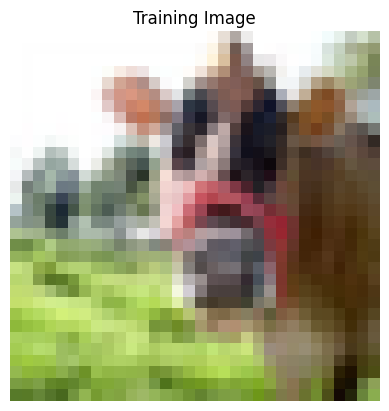

label 11


In [ ]:

plt.imshow(x_train[0])
plt.title("Training Image")
plt.axis("off")
plt.show()


print("label", y_train[0][0])


In [ ]:

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum", x_train.min())
print("Maximum", x_train.max())


Minimum 0.0
Maximum 1.0


In [ ]:


from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

inputs = Input(shape=(32, 32, 3))
x = Conv2D(16, (3, 3), activation="relu")(inputs)
x = Conv2D(16, (3, 3), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation="relu")(x)
x = Conv2D(32, (3, 3), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64, activation="relu")(x)
outputs = Dense(20, activation="softmax")(x)

model1 = Model(inputs=inputs, outputs=outputs)

model1.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 10, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,220 (270.39 KB)

 Trainable params: 69,220 (270.39 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("done")


done


In [ ]:

history1 = model1.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 21ms/step - accuracy: 0.2164 - loss: 2.5410 - val_accuracy: 0.3047 - val_loss: 2.2651
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3261 - loss: 2.1822 - val_accuracy: 0.3394 - val_loss: 2.1392
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3668 - loss: 2.0417 - val_accuracy: 0.3707 - val_loss: 2.0250
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4018 - loss: 1.9425 - val_accuracy: 0.3909 - val_loss: 1.9658
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4249 - loss: 1.8553 - val_accuracy: 0.4136 - val_loss: 1.9084


In [ ]:

test_loss, test_accuracy = model1.evaluate(x_test, y_test)

print("Accuracy:", round(test_accuracy * 100, 2),)
print("Loss:", round(test_loss, 4))


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4066 - loss: 1.9213
Accuracy: 40.66
Loss: 1.9213


The first model is a basic CNN using 5 hidden layers and ReLU activation. I trained the model for 5 epochs using the Adam optimizer. The model finished with 42.49% training accuracy, 41.36% validation accuracy, and 40.66% test accuracy. The model increased in acuracy after each epoch so it was learning. But the overall acuracy was fairtly low with 42.49%

In [ ]:

# Model 2 Increasing the number of filters

inputs = Input(shape=(32, 32, 3))
x = Conv2D(32, (3, 3), activation="relu")(inputs)
x = Conv2D(32, (3, 3), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), activation="relu")(x)
x = Conv2D(64, (3, 3), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64, activation="relu")(x)
outputs = Dense(20, activation="softmax")(x)

model2 = Model(inputs=inputs, outputs=outputs)

model2.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,332 (661.45 KB)

 Trainable params: 169,332 (661.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model2.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.2016 - loss: 2.5781 - val_accuracy: 0.2669 - val_loss: 2.3697
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3120 - loss: 2.2290 - val_accuracy: 0.3316 - val_loss: 2.1970
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3595 - loss: 2.0670 - val_accuracy: 0.3632 - val_loss: 2.0616
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3959 - loss: 1.9470 - val_accuracy: 0.3921 - val_loss: 1.9555
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4248 - loss: 1.8453 - val_accuracy: 0.4180 - val_loss: 1.8931


After adding more filters to the second model there was not a huge diffrence in acruacy %


In [ ]:

from tensorflow.keras.layers import LeakyReLU


inputs = Input(shape=(32, 32, 3))

x = Conv2D(32, (3, 3))(inputs)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(32, (3, 3))(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3))(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(64, (3, 3))(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64)(x)
x = LeakyReLU(negative_slope=0.1)(x)

outputs = Dense(20, activation="softmax")(x)

model3 = Model(inputs=inputs, outputs=outputs)

model3.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,332 (661.45 KB)

 Trainable params: 169,332 (661.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history3 = model3.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.2550 - loss: 2.4133 - val_accuracy: 0.3444 - val_loss: 2.1322
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3945 - loss: 1.9624 - val_accuracy: 0.4222 - val_loss: 1.8790
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4577 - loss: 1.7344 - val_accuracy: 0.4647 - val_loss: 1.7328
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5072 - loss: 1.5651 - val_accuracy: 0.4970 - val_loss: 1.6345
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5473 - loss: 1.4426 - val_accuracy: 0.5011 - val_loss: 1.6211


Using Leaky RELU made the model increase its acuracy by 8.31%. Leaky relu allowed for samllnegative numbers to pass through. This may have been the reason for the increace in accruacy

In [ ]:

#Tanh Activation

inputs = Input(shape=(32, 32, 3))

x = Conv2D(32, (3, 3), activation="tanh")(inputs)
x = Conv2D(32, (3, 3), activation="tanh")(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), activation="tanh")(x)
x = Conv2D(64, (3, 3), activation="tanh")(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64, activation="tanh")(x)

outputs = Dense(20, activation="softmax")(x)

model_tanh = Model(inputs=inputs, outputs=outputs)

model_tanh.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,332 (661.45 KB)

 Trainable params: 169,332 (661.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model_tanh.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history_tanh = model_tanh.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.2774 - loss: 2.3659 - val_accuracy: 0.3498 - val_loss: 2.1216
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3955 - loss: 1.9734 - val_accuracy: 0.4048 - val_loss: 1.9140
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4437 - loss: 1.8055 - val_accuracy: 0.4322 - val_loss: 1.8435
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4807 - loss: 1.6855 - val_accuracy: 0.4377 - val_loss: 1.8227
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5046 - loss: 1.5941 - val_accuracy: 0.4509 - val_loss: 1.7983


I changed the activation function to tanh while keeping the same architecture and training settings. The model reached 50.46% training accuracy and 45.09% validation accuracy after 5 epochs. Leaky RELU still performed better

In [ ]:

#Sigmoid Activation

inputs = Input(shape=(32, 32, 3))
x = Conv2D(32, (3, 3), activation="sigmoid")(inputs)
x = Conv2D(32, (3, 3), activation="sigmoid")(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), activation="sigmoid")(x)
x = Conv2D(64, (3, 3), activation="sigmoid")(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64, activation="sigmoid")(x)

outputs = Dense(20, activation="softmax")(x)

model_sigmoid = Model(inputs=inputs, outputs=outputs)

model_sigmoid.summary()


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,332 (661.45 KB)

 Trainable params: 169,332 (661.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model_sigmoid.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_sigmoid = model_sigmoid.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.0508 - loss: 3.0029 - val_accuracy: 0.1030 - val_loss: 2.9413
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1591 - loss: 2.7181 - val_accuracy: 0.1835 - val_loss: 2.6338
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.2069 - loss: 2.5574 - val_accuracy: 0.2146 - val_loss: 2.5408
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2423 - loss: 2.4589 - val_accuracy: 0.2429 - val_loss: 2.4406
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2654 - loss: 2.3777 - val_accuracy: 0.2665 - val_loss: 2.3495


Signmoid performed very terribly compaired to Leaky RELU and tanh. It by far had the worst accuracy percentage. This might be sigmoid can cause vanishing gradients, making it harder for the network to update its weights

In [ ]:

from tensorflow.keras.layers import BatchNormalization

#Batch Normalization

inputs = Input(shape=(32, 32, 3))

x = Conv2D(32, (3, 3))(inputs)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(32, (3, 3))(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3))(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(64, (3, 3))(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64)(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)

outputs = Dense(20, activation="softmax")(x)

model4 = Model(inputs=inputs, outputs=outputs)

model4.summary()


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170,356 (665.45 KB)

 Trainable params: 169,844 (663.45 KB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:

model4.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history4 = model4.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.3436 - loss: 2.1443 - val_accuracy: 0.3589 - val_loss: 2.0812
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4651 - loss: 1.7191 - val_accuracy: 0.4291 - val_loss: 1.8504
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5224 - loss: 1.5245 - val_accuracy: 0.4709 - val_loss: 1.7036
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5660 - loss: 1.3807 - val_accuracy: 0.5003 - val_loss: 1.6436
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6033 - loss: 1.2617 - val_accuracy: 0.4966 - val_loss: 1.6651


I added batch layers to my Leaky RELU model. The Training accuracy increased but the validation accuracy is low and decresed from apoch 4 to 5. this could be an early sign of overfitting.

In [ ]:

from tensorflow.keras.layers import Dropout

#Batch Normalization and Dropout

inputs = Input(shape=(32, 32, 3))
x = Conv2D(32, (3, 3))(inputs)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(32, (3, 3))(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3))(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(64, (3, 3))(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64)(x)
x = BatchNormalization()(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Dropout(0.3)(x)

outputs = Dense(20, activation="softmax")(x)

model5 = Model(inputs=inputs, outputs=outputs)

model5.summary()


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170,356 (665.45 KB)

 Trainable params: 169,844 (663.45 KB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:

model5.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history5 = model5.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.2845 - loss: 2.3497 - val_accuracy: 0.3257 - val_loss: 2.1785
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3994 - loss: 1.9356 - val_accuracy: 0.3763 - val_loss: 2.0337
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.4542 - loss: 1.7493 - val_accuracy: 0.4501 - val_loss: 1.7733
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4894 - loss: 1.6291 - val_accuracy: 0.4719 - val_loss: 1.7206
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5193 - loss: 1.5257 - val_accuracy: 0.4887 - val_loss: 1.6347


Drop out made the training accruacy decreese but the validation loss improved. Drop out could be a way of improving dropout compaired to batch.

In [ ]:

# He Initialization

inputs = Input(shape=(32, 32, 3))
x = Conv2D(32, (3, 3), kernel_initializer="he_normal")(inputs)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(32, (3, 3), kernel_initializer="he_normal")(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), kernel_initializer="he_normal")(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = Conv2D(64, (3, 3), kernel_initializer="he_normal")(x)
x = LeakyReLU(negative_slope=0.1)(x)
x = MaxPooling2D((2, 2))(x)
x = Flatten()(x)
x = Dense(64, kernel_initializer="he_normal")(x)
x = LeakyReLU(negative_slope=0.1)(x)

outputs = Dense(20, activation="softmax")(x)

model6 = Model(inputs=inputs, outputs=outputs)

model6.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_16 (LeakyReLU)      │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,332 (661.45 KB)

 Trainable params: 169,332 (661.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model6.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history6 = model6.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.2655 - loss: 2.3955 - val_accuracy: 0.3487 - val_loss: 2.1023
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3983 - loss: 1.9431 - val_accuracy: 0.4229 - val_loss: 1.8513
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4752 - loss: 1.6889 - val_accuracy: 0.4593 - val_loss: 1.7485
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5289 - loss: 1.4993 - val_accuracy: 0.4931 - val_loss: 1.6494
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5765 - loss: 1.3445 - val_accuracy: 0.5009 - val_loss: 1.6011


He gave me the best training accuracy so far while keeping teh same leaky RELU model.It prefdormed better then the intial xavier model in everything other then validation loss

In [ ]:

#compile both SGD and ADAM
model_adam = tf.keras.models.clone_model(model6)
model_sgd = tf.keras.models.clone_model(model6)

model_sgd.set_weights(model_adam.get_weights())

model_adam.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_sgd.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("done")


done


In [ ]:

history_adam = model_adam.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    shuffle=False
)

print("SGD")

history_sgd = model_sgd.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    shuffle=False
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6487 - loss: 1.1085 - val_accuracy: 0.4506 - val_loss: 1.9829
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6758 - loss: 1.0231 - val_accuracy: 0.4586 - val_loss: 2.0135
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6979 - loss: 0.9404 - val_accuracy: 0.4580 - val_loss: 2.1394
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7200 - loss: 0.8651 - val_accuracy: 0.4515 - val_loss: 2.3021
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7376 - loss: 0.7998 - val_accuracy: 0.4410 - val_loss: 2.5092
SGD
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2014 - loss: 2.6132 - val_accuracy: 0.2018 - val_loss: 2.6058
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.2139 - loss: 2.5769 - val_accuracy: 0.2142 - val_loss: 2.5696
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2250 - loss: 2.5423 - val_accuracy: 0.2251

In [ ]:

# Compare loss after each epoch
print("Epoch | Adam Loss | SGD Loss")

for i in range(5):
    adam_loss = history_adam.history["loss"][i]
    sgd_loss = history_sgd.history["loss"][i]

    print(f"{i+1}     | {adam_loss:.4f}    | {sgd_loss:.4f}")

print("\nAdam Validation Accuracy:",
      round(history_adam.history["val_accuracy"][-1] * 100, 2), "%")

print("SGD Validation Accuracy:",
      round(history_sgd.history["val_accuracy"][-1] * 100, 2), "%")


Epoch | Adam Loss | SGD Loss
1     | 1.1085    | 2.6132
2     | 1.0231    | 2.5769
3     | 0.9404    | 2.5423
4     | 0.8651    | 2.5122
5     | 0.7998    | 2.4855

Adam Validation Accuracy: 44.1 %
SGD Validation Accuracy: 24.25 %


ADAM learns faster and achived higher validation accruacy. I used learning rate of 0.001 for both which could be to small for SGD to train on. But for the features I used ADAM performed better.

Summary

Leaky RELU performed the best with 50.11% validation accruacy. SIgmoid performed the worst with 26.65%. Increaseing filters didn't seem top help in the instant. Batch normilazation increased accuracy but showed early signs of over fitting. Dropout helped reduce the gap between Training and validation accuracy.Adam also performed much better than SGD, learning faster and reaching higher accuracy with the settings I used.

Adding more layers or parameters doesn't always improve a model. Choosing the right activation functions and training settings can help.
